In [1]:
print("hello world")

hello world


### Convolution

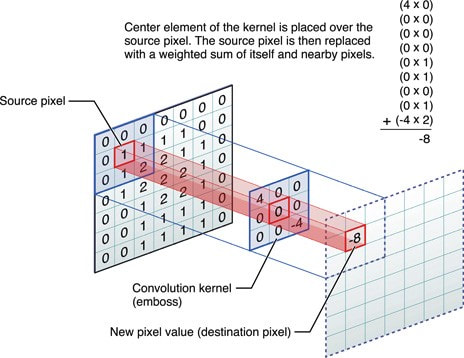

In [ ]:
from PIL import Image
img = Image.open("convolution.jpeg")
img

In [18]:
# Implementing simple convolution
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

img = Image.open("ishowspeed.webp").convert("L")
transform = transforms.ToTensor()

img_tensor = transform(img)
print('Shape after transform', img_tensor.shape)

kernel_matrix = [
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
]
constant = 16
blur_kernel = [
    [1/constant, 2/constant, 1/constant],
    [2/constant, 4/constant, 2/constant],
    [1/constant, 2/constant, 1/constant]
]
custom_kernel = torch.tensor(blur_kernel, dtype=torch.float32)
custom_kernel = custom_kernel.view(1, 1, 3, 3)

# adding batch dimension at the beginning
# img_tensor = img_tensor.unsqueeze(0)
print(" Shape with batch dimension", img_tensor.shape)

conv_layer = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1, bias=False)

conv_layer.weight = nn.Parameter(custom_kernel)

# conv_layer.weight.requires_grad = False

with torch.no_grad():
    output_tensor = conv_layer(img_tensor)

print("Output shape: ", output_tensor.shape)

Shape after transform torch.Size([1, 720, 1280])
 Shape with batch dimension torch.Size([1, 720, 1280])
Output shape:  torch.Size([1, 720, 1280])


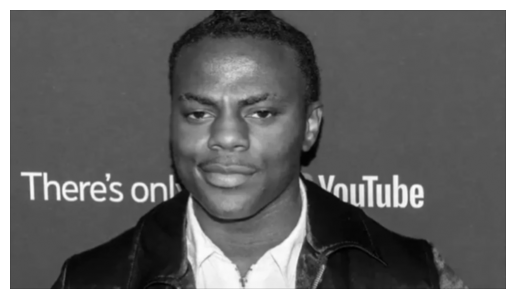

In [19]:
feature_map = output_tensor.squeeze().numpy()

# Display the feature map as a grayscale image
plt.imshow(feature_map, cmap="gray")
plt.axis("off")
plt.show()